# Wetteranalyse Berlin

Dieses Notebook lädt historische Tageswerte für Berlin über die kostenlose Open-Meteo-Archiv-API und untersucht Temperatur und Niederschlag. Die API benötigt keinen Schlüssel, aber eine Internetverbindung. Der Zeitraum kann unten angepasst werden.

Datenquelle: Open-Meteo Historical Weather API. Berlin wird mit den Koordinaten 52.52° N, 13.405° E angenähert. Temperaturen sind in °C, Niederschlag in mm angegeben.

## 1. Bibliotheken importieren

`pandas` organisiert die Tabelle, `matplotlib` zeichnet Diagramme und `requests` ruft die Wetter-API ab.

Falls ein Paket noch fehlt, installiere die Abhängigkeiten in einer Notebook-Zelle mit `%pip install pandas matplotlib requests`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import requests

## 2. Wetterdaten laden (API)

Wir verwenden die Open-Meteo-Archiv-API. Das Beispiel lädt Tageswerte für 2025; ändere Start- und Enddatum, um einen anderen abgeschlossenen Zeitraum auszuwerten.

In [2]:
latitude = 52.52
longitude = 13.405
start_date = "2025-01-01"
end_date = "2025-12-31"

api_url = "https://archive-api.open-meteo.com/v1/archive"
parameters = {
    "latitude": latitude,
    "longitude": longitude,
    "start_date": start_date,
    "end_date": end_date,
    "daily": [
        "temperature_2m_max",
        "temperature_2m_min",
        "temperature_2m_mean",
        "precipitation_sum",
    ],
    "timezone": "Europe/Berlin",
}

try:
    response = requests.get(api_url, params=parameters, timeout=30)
    response.raise_for_status()
    weather_json = response.json()
except requests.RequestException as error:
    raise RuntimeError(
        "Wetterdaten konnten nicht geladen werden. Prüfe Internetverbindung "
        "und Datumsbereich."
    ) from error

if weather_json.get("error"):
    raise ValueError(weather_json.get("reason", "Fehler in der API-Anfrage"))

daily_data = weather_json.get("daily")
if not daily_data or not daily_data.get("time"):
    raise ValueError("Die API hat für diesen Zeitraum keine Tagesdaten geliefert.")

weather_df = pd.DataFrame(daily_data).rename(
    columns={
        "time": "datum",
        "temperature_2m_max": "temperatur_max_c",
        "temperature_2m_min": "temperatur_min_c",
        "temperature_2m_mean": "temperatur_mittel_c",
        "precipitation_sum": "niederschlag_mm",
    }
 )
weather_df["datum"] = pd.to_datetime(weather_df["datum"])
weather_df.head()

,datum,temperatur_max_c,temperatur_min_c,temperatur_mittel_c,niederschlag_mm
0,2025-01-01,6.9,0.6,4.8,0.1
1,2025-01-02,6.7,0.9,4.0,4.1
2,2025-01-03,2.4,-1.5,0.8,3.1
3,2025-01-04,0.8,-2.7,-1.1,0.0
4,2025-01-05,1.4,-2.5,-1.0,9.3


## 3. Datenüberblick und erste Auswertung

Zuerst prüfen wir Stichproben, Datentypen und fehlende Werte. `describe()` gibt grundlegende Kennzahlen wie Mittelwert, Streuung sowie Minimum und Maximum aus.

In [3]:
print(f"Zeitraum: {weather_df['datum'].min().date()} bis {weather_df['datum'].max().date()}")
print(f"Anzahl der Tage: {len(weather_df)}")
display(weather_df.head())

print("Fehlende Werte pro Spalte:")
display(weather_df.isna().sum().to_frame("fehlende_werte"))

print("Grundlegende Statistiken:")
weather_df[[
    "temperatur_max_c",
    "temperatur_min_c",
    "temperatur_mittel_c",
    "niederschlag_mm",
]].describe().round(2)

Zeitraum: 2025-01-01 bis 2025-12-31
Anzahl der Tage: 365


,datum,temperatur_max_c,temperatur_min_c,temperatur_mittel_c,niederschlag_mm
0,2025-01-01,6.9,0.6,4.8,0.1
1,2025-01-02,6.7,0.9,4.0,4.1
2,2025-01-03,2.4,-1.5,0.8,3.1
3,2025-01-04,0.8,-2.7,-1.1,0.0
4,2025-01-05,1.4,-2.5,-1.0,9.3


Fehlende Werte pro Spalte:


,fehlende_werte
datum,0
temperatur_max_c,0
temperatur_min_c,0
temperatur_mittel_c,0
niederschlag_mm,0


Grundlegende Statistiken:


,temperatur_max_c,temperatur_min_c,temperatur_mittel_c,niederschlag_mm
count,365.00,365.00,365.00,365.00
mean,14.67,6.72,10.65,1.67
std,8.40,6.69,7.45,3.84
min,-4.30,-13.30,-7.40,0.00
25%,7.80,1.40,4.80,0.00
50%,14.90,6.70,10.80,0.10
75%,21.50,12.50,17.10,1.70
max,37.60,20.20,29.90,44.80


## 4. Temperaturverlauf visualisieren

Das Liniendiagramm zeigt Tageshöchst- und -tiefsttemperaturen. Die wärmste Tageshöchsttemperatur und die niedrigste Tagestiefsttemperatur werden im Diagramm markiert.

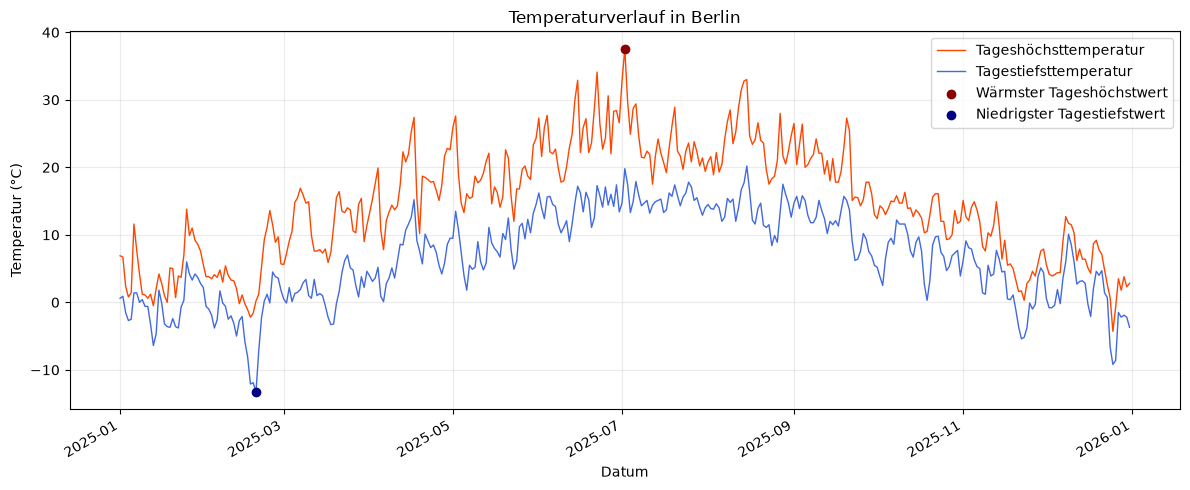

In [4]:
temperature_df = weather_df.dropna(
    subset=["temperatur_max_c", "temperatur_min_c"]
 ).copy()

if temperature_df.empty:
    raise ValueError("Für den Zeitraum sind keine Temperaturwerte vorhanden.")

warmest_idx = temperature_df["temperatur_max_c"].idxmax()
coldest_idx = temperature_df["temperatur_min_c"].idxmin()

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(
    temperature_df["datum"],
    temperature_df["temperatur_max_c"],
    label="Tageshöchsttemperatur",
    color="orangered",
    linewidth=1,
 )
ax.plot(
    temperature_df["datum"],
    temperature_df["temperatur_min_c"],
    label="Tagestiefsttemperatur",
    color="royalblue",
    linewidth=1,
 )
ax.scatter(
    temperature_df.loc[warmest_idx, "datum"],
    temperature_df.loc[warmest_idx, "temperatur_max_c"],
    color="darkred",
    zorder=3,
    label="Wärmster Tageshöchstwert",
 )
ax.scatter(
    temperature_df.loc[coldest_idx, "datum"],
    temperature_df.loc[coldest_idx, "temperatur_min_c"],
    color="navy",
    zorder=3,
    label="Niedrigster Tagestiefstwert",
 )
ax.set_title("Temperaturverlauf in Berlin")
ax.set_xlabel("Datum")
ax.set_ylabel("Temperatur (°C)")
ax.grid(alpha=0.25)
ax.legend()
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

## 5. Niederschlagsanalyse

Wir summieren den Niederschlag über den Zeitraum und zählen Regentage als Tage mit mindestens 1 mm Niederschlag. Das Balkendiagramm fasst die Werte pro Monat zusammen, damit die Darstellung bei langen Zeiträumen lesbar bleibt.

Niederschlag insgesamt: 610.5 mm
Regentage (mindestens 1 mm): 115


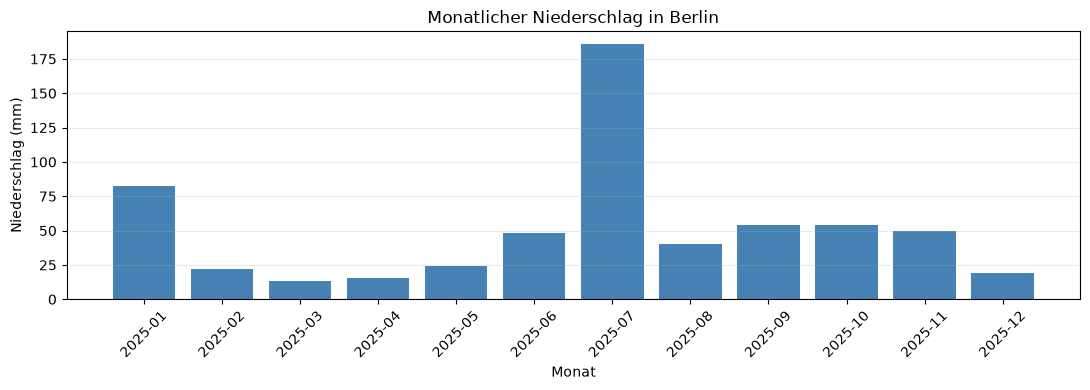

In [5]:
precipitation_df = weather_df.dropna(subset=["niederschlag_mm"]).copy()

if precipitation_df.empty:
    raise ValueError("Für den Zeitraum sind keine Niederschlagswerte vorhanden.")

total_precipitation = precipitation_df["niederschlag_mm"].sum()
rainy_days = (precipitation_df["niederschlag_mm"] >= 1).sum()
monthly_precipitation = precipitation_df.groupby(
    precipitation_df["datum"].dt.to_period("M")
 )["niederschlag_mm"].sum()
monthly_precipitation.index = monthly_precipitation.index.astype(str)

print(f"Niederschlag insgesamt: {total_precipitation:.1f} mm")
print(f"Regentage (mindestens 1 mm): {rainy_days}")

fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(monthly_precipitation.index, monthly_precipitation.values, color="steelblue")
ax.set_title("Monatlicher Niederschlag in Berlin")
ax.set_xlabel("Monat")
ax.set_ylabel("Niederschlag (mm)")
ax.grid(axis="y", alpha=0.25)
plt.xticks(rotation=45)
fig.tight_layout()
plt.show()

## 6. Extreme Werte und Statistiken berechnen

Die Übersicht fasst Mittelwert, Median, Minimum, Maximum und Standardabweichung zusammen. Zusätzlich geben wir die Daten der wärmsten und kältesten Tage aus.

In [6]:
statistics_df = weather_df[
    [
        "temperatur_max_c",
        "temperatur_min_c",
        "temperatur_mittel_c",
        "niederschlag_mm",
    ]
 ].agg(["mean", "median", "min", "max", "std"]).T.round(2)

display(statistics_df)
print(
    "Wärmster Tag (höchste Tageshöchsttemperatur): "
    f"{weather_df.loc[warmest_idx, 'datum'].date()} "
    f"({weather_df.loc[warmest_idx, 'temperatur_max_c']:.1f} °C)"
 )
print(
    "Kältester Tag (niedrigste Tagestiefsttemperatur): "
    f"{weather_df.loc[coldest_idx, 'datum'].date()} "
    f"({weather_df.loc[coldest_idx, 'temperatur_min_c']:.1f} °C)"
 )

,mean,median,min,max,std
temperatur_max_c,14.67,14.9,-4.3,37.6,8.40
temperatur_min_c,6.72,6.7,-13.3,20.2,6.69
temperatur_mittel_c,10.65,10.8,-7.4,29.9,7.45
niederschlag_mm,1.67,0.1,0.0,44.8,3.84


Wärmster Tag (höchste Tageshöchsttemperatur): 2025-07-02 (37.6 °C)
Kältester Tag (niedrigste Tagestiefsttemperatur): 2025-02-19 (-13.3 °C)


## 7. Korrelation zwischen Temperatur und Niederschlag

Wir berechnen die Pearson-Korrelation zwischen Tagesmitteltemperatur und Niederschlag und stellen die Werte als Streudiagramm dar. Der Koeffizient beschreibt einen linearen Zusammenhang, beweist aber keine Ursache-Wirkung-Beziehung.

Pearson-Korrelation: 0.122


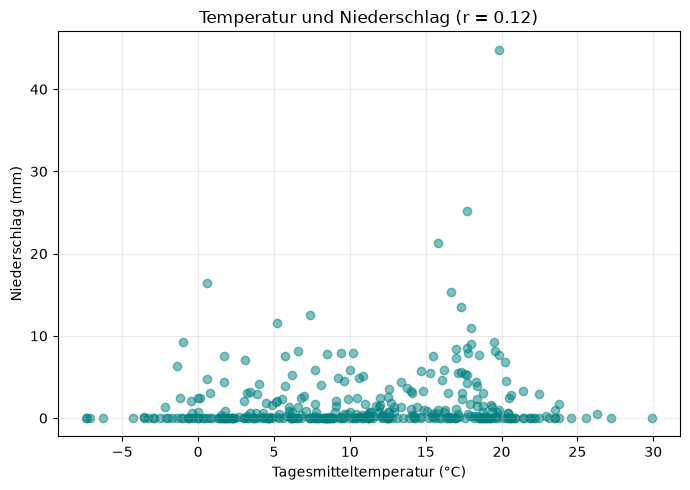

In [7]:
correlation_df = weather_df[
    ["temperatur_mittel_c", "niederschlag_mm"]
 ].dropna()

if len(correlation_df) < 2:
    raise ValueError("Für eine Korrelation werden mindestens zwei vollständige Tage benötigt.")

correlation = correlation_df[
    "temperatur_mittel_c"
 ].corr(correlation_df["niederschlag_mm"])
print(f"Pearson-Korrelation: {correlation:.3f}")

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(
    correlation_df["temperatur_mittel_c"],
    correlation_df["niederschlag_mm"],
    alpha=0.5,
    color="teal",
 )
ax.set_title(f"Temperatur und Niederschlag (r = {correlation:.2f})")
ax.set_xlabel("Tagesmitteltemperatur (°C)")
ax.set_ylabel("Niederschlag (mm)")
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

### Ergebnisse einordnen

Vergleiche den Temperaturverlauf mit den niederschlagsreichen Monaten und prüfe, ob das Streudiagramm einen erkennbaren Trend zeigt. Die Korrelation kann nahe 0 liegen oder von Extremtagen beeinflusst werden. Die Ergebnisse beziehen sich nur auf den oben eingestellten Zeitraum und sind keine Wettervorhersage.

## 8. Vergleich mit DWD-Messdaten

Zum Vergleich laden wir die Stationsmessungen von **Berlin-Tempelhof (DWD-ID 00433)** aus dem DWD Climate Data Center. Wir vergleichen nur gemeinsame Tage im eingestellten Zeitraum. Open-Meteo liefert hier Werte für ein Koordinatenraster, der DWD misst direkt an einer Station; kleine Abweichungen sind daher zu erwarten.

In [8]:
from io import BytesIO
from zipfile import ZipFile

dwd_url = (
    "https://opendata.dwd.de/climate_environment/CDC/observations_germany/"
    "climate/daily/kl/historical/"
    "tageswerte_KL_00433_19480101_20251231_hist.zip"
 )

dwd_response = requests.get(dwd_url, timeout=60)
dwd_response.raise_for_status()

with ZipFile(BytesIO(dwd_response.content)) as dwd_archive:
    dwd_csv_name = next(
        name
        for name in dwd_archive.namelist()
        if name.startswith("produkt_klima_tag_") and name.endswith(".txt")
    )
    with dwd_archive.open(dwd_csv_name) as dwd_csv:
        dwd_raw = pd.read_csv(
            dwd_csv,
            sep=";",
            skipinitialspace=True,
            na_values=[-999, "-999"],
            low_memory=False,
        )

dwd_raw.columns = dwd_raw.columns.str.strip()
dwd_raw["MESS_DATUM"] = dwd_raw["MESS_DATUM"].astype("string").str.strip()
dwd_df = dwd_raw[["MESS_DATUM", "TXK", "TNK", "TMK", "RSK"]].copy()
dwd_df["datum"] = pd.to_datetime(
    dwd_df.pop("MESS_DATUM"),
    format="%Y%m%d",
    errors="coerce",
 )
dwd_df = dwd_df.rename(
    columns={
        "TXK": "dwd_temperatur_max_c",
        "TNK": "dwd_temperatur_min_c",
        "TMK": "dwd_temperatur_mittel_c",
        "RSK": "dwd_niederschlag_mm",
    }
 )

start_timestamp = pd.Timestamp(start_date)
end_timestamp = pd.Timestamp(end_date)
dwd_df = dwd_df[
    dwd_df["datum"].between(start_timestamp, end_timestamp)
 ].dropna(subset=["datum"])

if dwd_df.empty:
    raise ValueError(
        "Für den ausgewählten Zeitraum enthält die DWD-Historie keine Daten. "
        "Die verwendete Stationsdatei reicht bis 2025-12-31."
    )

print(f"DWD-Station: Berlin-Tempelhof (00433)")
print(f"DWD-Tage im gewählten Zeitraum: {len(dwd_df)}")
display(dwd_df.head())

DWD-Station: Berlin-Tempelhof (00433)
DWD-Tage im gewählten Zeitraum: 365


,dwd_temperatur_max_c,dwd_temperatur_min_c,dwd_temperatur_mittel_c,dwd_niederschlag_mm,datum
28125,8.5,2.0,5.5,0.8,2025-01-01
28126,8.4,2.0,4.6,0.2,2025-01-02
28127,3.8,-1.0,1.4,0.4,2025-01-03
28128,0.6,-0.8,0.0,0.0,2025-01-04
28129,1.2,-2.6,-0.8,10.9,2025-01-05


Gemeinsame Vergleichstage: 365


,Vergleichstage,Bias Open-Meteo - DWD,Mittlere absolute Abweichung
Messgröße,,,
Tageshöchsttemperatur (°C),365,-0.95,1.14
Tagestiefsttemperatur (°C),365,0.25,0.84
Tagesmitteltemperatur (°C),365,-0.45,0.63
Niederschlag (mm),365,0.42,1.01


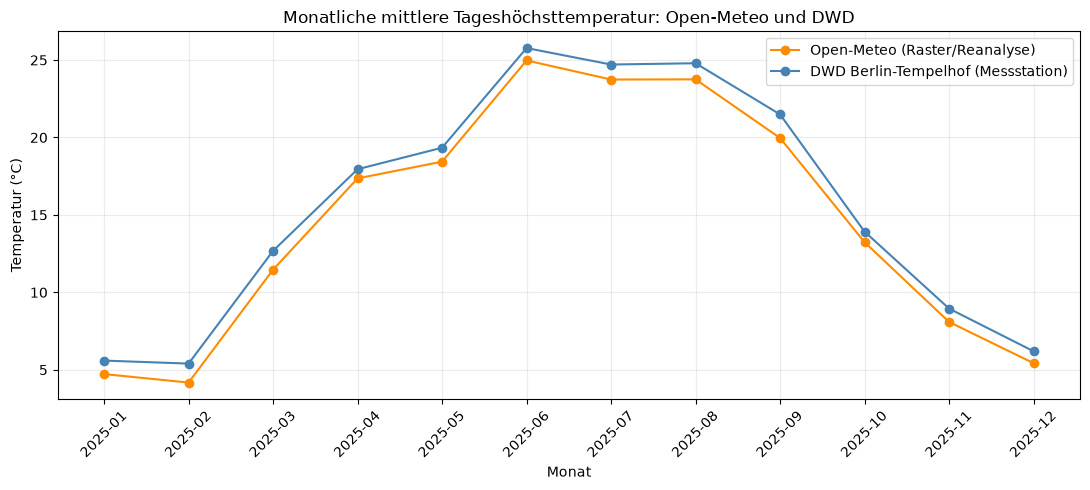

In [9]:
comparison_df = pd.merge(
    weather_df,
    dwd_df,
    on="datum",
    how="inner",
 ).sort_values("datum")

if comparison_df.empty:
    raise ValueError("Für Open-Meteo und DWD gibt es keine gemeinsamen Tage.")

print(f"Gemeinsame Vergleichstage: {len(comparison_df)}")

comparison_fields = [
    ("Tageshöchsttemperatur (°C)", "temperatur_max_c", "dwd_temperatur_max_c"),
    ("Tagestiefsttemperatur (°C)", "temperatur_min_c", "dwd_temperatur_min_c"),
    ("Tagesmitteltemperatur (°C)", "temperatur_mittel_c", "dwd_temperatur_mittel_c"),
    ("Niederschlag (mm)", "niederschlag_mm", "dwd_niederschlag_mm"),
]
comparison_rows = []

for label, openmeteo_column, dwd_column in comparison_fields:
    valid_pairs = comparison_df[[openmeteo_column, dwd_column]].dropna()
    if valid_pairs.empty:
        continue
    difference = valid_pairs[openmeteo_column] - valid_pairs[dwd_column]
    comparison_rows.append(
        {
            "Messgröße": label,
            "Vergleichstage": len(valid_pairs),
            "Bias Open-Meteo - DWD": difference.mean(),
            "Mittlere absolute Abweichung": difference.abs().mean(),
        }
    )

comparison_stats = pd.DataFrame(comparison_rows).set_index("Messgröße").round(2)
display(comparison_stats)

monthly_comparison = comparison_df.groupby(
    comparison_df["datum"].dt.to_period("M")
 )[["temperatur_max_c", "dwd_temperatur_max_c"]].mean()
monthly_comparison.index = monthly_comparison.index.astype(str)

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(
    monthly_comparison.index,
    monthly_comparison["temperatur_max_c"],
    marker="o",
    label="Open-Meteo (Raster/Reanalyse)",
    color="darkorange",
 )
ax.plot(
    monthly_comparison.index,
    monthly_comparison["dwd_temperatur_max_c"],
    marker="o",
    label="DWD Berlin-Tempelhof (Messstation)",
    color="steelblue",
 )
ax.set_title("Monatliche mittlere Tageshöchsttemperatur: Open-Meteo und DWD")
ax.set_xlabel("Monat")
ax.set_ylabel("Temperatur (°C)")
ax.grid(alpha=0.25)
ax.legend()
plt.xticks(rotation=45)
fig.tight_layout()
plt.show()

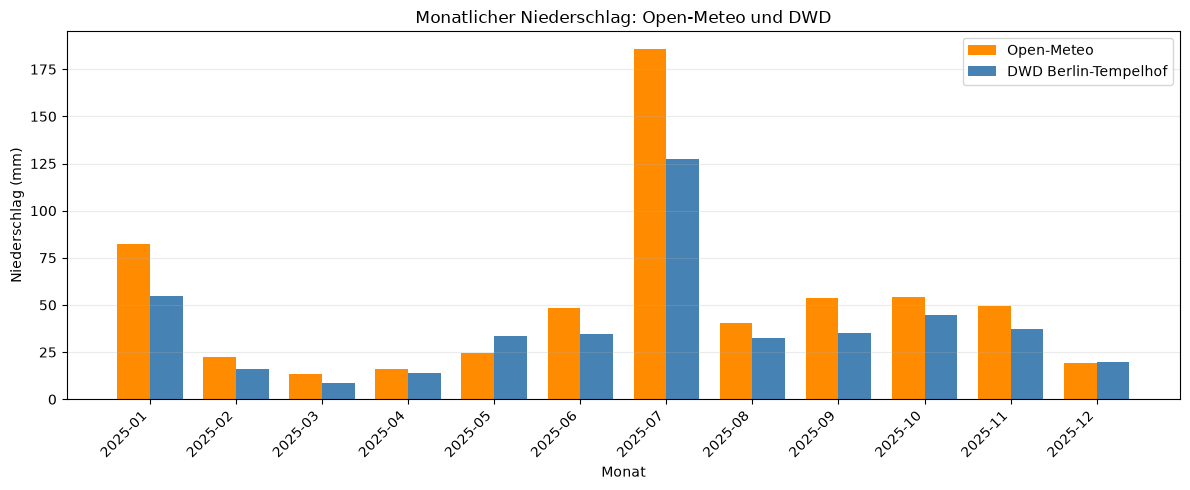

In [10]:
monthly_rain_comparison = (
    comparison_df.assign(monat=comparison_df["datum"].dt.to_period("M"))
    .groupby("monat")[["niederschlag_mm", "dwd_niederschlag_mm"]]
    .sum(min_count=1)
 )
month_labels = monthly_rain_comparison.index.astype(str)
bar_positions = list(range(len(month_labels)))
bar_width = 0.38

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(
    [position - bar_width / 2 for position in bar_positions],
    monthly_rain_comparison["niederschlag_mm"],
    width=bar_width,
    label="Open-Meteo",
    color="darkorange",
 )
ax.bar(
    [position + bar_width / 2 for position in bar_positions],
    monthly_rain_comparison["dwd_niederschlag_mm"],
    width=bar_width,
    label="DWD Berlin-Tempelhof",
    color="steelblue",
 )
ax.set_title("Monatlicher Niederschlag: Open-Meteo und DWD")
ax.set_xlabel("Monat")
ax.set_ylabel("Niederschlag (mm)")
ax.set_xticks(bar_positions)
ax.set_xticklabels(month_labels, rotation=45, ha="right")
ax.grid(axis="y", alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()

**Interpretation:** Der Bias ist `Open-Meteo minus DWD`; ein negativer Temperatur-Bias bedeutet, dass Open-Meteo im Mittel niedrigere Werte liefert. Die mittlere absolute Abweichung (MAE) beschreibt den durchschnittlichen Abstand unabhängig vom Vorzeichen. Unterschiede sind erwartbar, da ein Raster-/Reanalysewert nicht exakt einer Stationsmessung entspricht. Die hier verwendete DWD-Historie reicht bis 2025-12-31.

## 9. Letzte zwei Wochen in Berlin

Diese Grafik verwendet die aktuellsten verfügbaren Tagesmessungen der DWD-Station Berlin-Tempelhof. Der Zeitraum umfasst genau 14 Kalendertage und endet am jüngsten Datum in der DWD-Datei; die Daten können deshalb gegenüber dem heutigen Datum leicht verzögert sein. Temperatur und Niederschlag stehen auf getrennten Diagrammachsen.

DWD-Zeitraum: 2026-10-19 bis 2026-11-01 (14 Kalendertage)
Höchste Temperatur: 15.5 °C am 2026-10-27
Niedrigste Temperatur: 3.6 °C am 2026-10-28
Durchschnittliche Tagestemperatur: 9.5 °C
Niederschlagssumme: 15.1 mm; Regentage (mindestens 1 mm): 2


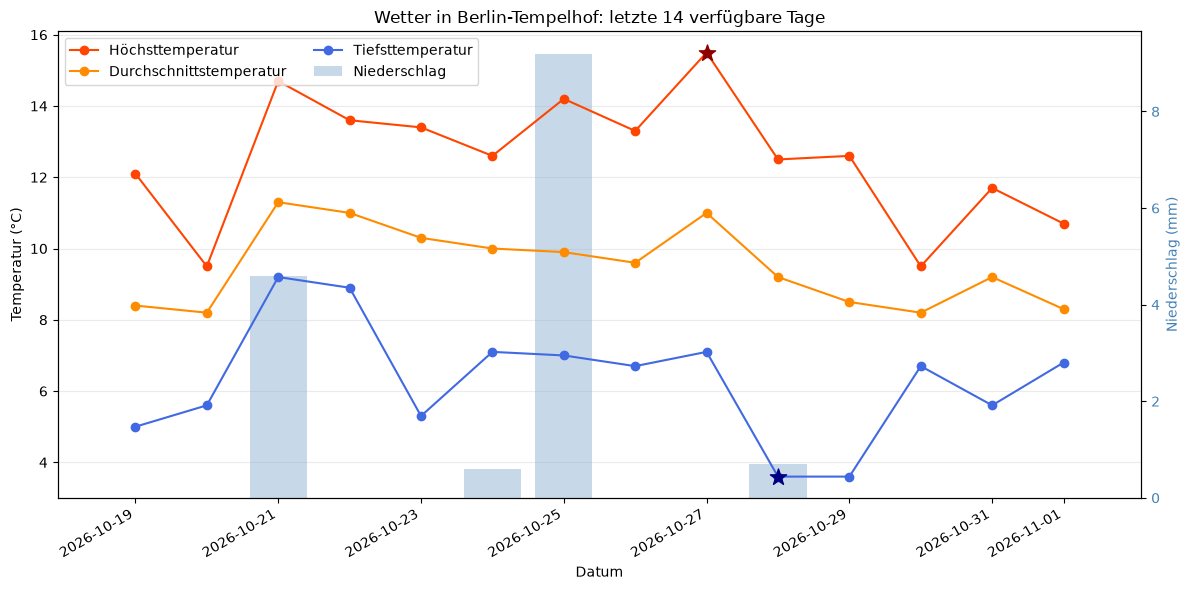

In [12]:
dwd_recent_url = (
    "https://opendata.dwd.de/climate_environment/CDC/observations_germany/"
    "climate/daily/kl/recent/tageswerte_KL_00433_akt.zip"
 )
recent_response = requests.get(dwd_recent_url, timeout=60)
recent_response.raise_for_status()

with ZipFile(BytesIO(recent_response.content)) as recent_archive:
    recent_csv_name = next(
        name
        for name in recent_archive.namelist()
        if name.startswith("produkt_klima_tag_") and name.endswith(".txt")
    )
    with recent_archive.open(recent_csv_name) as recent_csv:
        recent_raw = pd.read_csv(
            recent_csv,
            sep=";",
            skipinitialspace=True,
            na_values=[-999, "-999"],
            low_memory=False,
        )

recent_raw.columns = recent_raw.columns.str.strip()
last_two_weeks = recent_raw[["MESS_DATUM", "TXK", "TNK", "TMK", "RSK"]].copy()
last_two_weeks["datum"] = pd.to_datetime(
    last_two_weeks.pop("MESS_DATUM").astype("string").str.strip(),
    format="%Y%m%d",
    errors="coerce",
 )
last_two_weeks = last_two_weeks.rename(
    columns={
        "TXK": "temperatur_max_c",
        "TNK": "temperatur_min_c",
        "TMK": "temperatur_mittel_c",
        "RSK": "niederschlag_mm",
    }
 )
for spalte in [
    "temperatur_max_c",
    "temperatur_min_c",
    "temperatur_mittel_c",
    "niederschlag_mm",
]:
    last_two_weeks[spalte] = pd.to_numeric(last_two_weeks[spalte], errors="coerce")

last_two_weeks = last_two_weeks.dropna(subset=["datum"]).sort_values("datum")
letzter_dwd_tag = last_two_weeks["datum"].max()
erster_dwd_tag = letzter_dwd_tag - pd.Timedelta(days=13)
last_two_weeks = last_two_weeks[
    last_two_weeks["datum"].between(erster_dwd_tag, letzter_dwd_tag)
 ].copy()

valid_temperatures = last_two_weeks.dropna(
    subset=["temperatur_max_c", "temperatur_min_c", "temperatur_mittel_c"]
 )
valid_precipitation = last_two_weeks["niederschlag_mm"].dropna()
if valid_temperatures.empty or valid_precipitation.empty:
    raise ValueError("Für die letzten 14 verfügbaren Tage fehlen Messwerte.")

warmest_recent = valid_temperatures.loc[
    valid_temperatures["temperatur_max_c"].idxmax()
 ]
coldest_recent = valid_temperatures.loc[
    valid_temperatures["temperatur_min_c"].idxmin()
 ]
average_recent = valid_temperatures["temperatur_mittel_c"].mean()
precipitation_recent_total = valid_precipitation.sum()
rainy_days_recent = (valid_precipitation >= 1).sum()

print(
    f"DWD-Zeitraum: {last_two_weeks['datum'].min().date()} bis "
    f"{last_two_weeks['datum'].max().date()} "
    f"({len(last_two_weeks)} Kalendertage)"
 )
print(
    f"Höchste Temperatur: {warmest_recent['temperatur_max_c']:.1f} °C "
    f"am {warmest_recent['datum'].date()}"
 )
print(
    f"Niedrigste Temperatur: {coldest_recent['temperatur_min_c']:.1f} °C "
    f"am {coldest_recent['datum'].date()}"
 )
print(f"Durchschnittliche Tagestemperatur: {average_recent:.1f} °C")
print(
    f"Niederschlagssumme: {precipitation_recent_total:.1f} mm; "
    f"Regentage (mindestens 1 mm): {rainy_days_recent}"
 )

fig, ax_temp = plt.subplots(figsize=(12, 6))
ax_rain = ax_temp.twinx()
ax_rain.set_zorder(ax_temp.get_zorder() - 1)
ax_temp.patch.set_visible(False)

ax_rain.bar(
    last_two_weeks["datum"],
    last_two_weeks["niederschlag_mm"],
    width=0.8,
    color="steelblue",
    alpha=0.3,
    label="Niederschlag",
 )
ax_rain.set_ylabel("Niederschlag (mm)", color="steelblue")
ax_rain.tick_params(axis="y", labelcolor="steelblue")
ax_rain.set_ylim(bottom=0)

ax_temp.plot(
    last_two_weeks["datum"],
    last_two_weeks["temperatur_max_c"],
    marker="o",
    label="Höchsttemperatur",
    color="orangered",
 )
ax_temp.plot(
    last_two_weeks["datum"],
    last_two_weeks["temperatur_mittel_c"],
    marker="o",
    label="Durchschnittstemperatur",
    color="darkorange",
 )
ax_temp.plot(
    last_two_weeks["datum"],
    last_two_weeks["temperatur_min_c"],
    marker="o",
    label="Tiefsttemperatur",
    color="royalblue",
 )
ax_temp.scatter(
    warmest_recent["datum"],
    warmest_recent["temperatur_max_c"],
    marker="*",
    s=150,
    color="darkred",
    zorder=4,
    label="_nolegend_",
 )
ax_temp.scatter(
    coldest_recent["datum"],
    coldest_recent["temperatur_min_c"],
    marker="*",
    s=150,
    color="navy",
    zorder=4,
    label="_nolegend_",
 )
ax_temp.set_title("Wetter in Berlin-Tempelhof: letzte 14 verfügbare Tage")
ax_temp.set_xlabel("Datum")
ax_temp.set_ylabel("Temperatur (°C)")
ax_temp.grid(axis="y", alpha=0.25)

temp_handles, temp_labels = ax_temp.get_legend_handles_labels()
rain_handles, rain_labels = ax_rain.get_legend_handles_labels()
ax_temp.legend(
    temp_handles + rain_handles,
    temp_labels + rain_labels,
    loc="upper left",
    ncol=2,
 )
fig.autofmt_xdate()
fig.tight_layout()
plt.show()